In [1]:
from google.colab import drive, userdata
import os, sys
drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
USER, REPO = "jeevithrao", "ML_AL_MC"
REPO_DIR = f"/content/{REPO}"
if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{USER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git remote set-url origin https://{TOKEN}@github.com/{USER}/{REPO}.git
!git config user.name "jeevithrao"
!git config user.email "138958136+jeevithrao@users.noreply.github.com"
!git pull origin main || echo "Repo is empty, nothing to pull yet."
sys.path.append(f"{REPO_DIR}/src")

Mounted at /content/drive
Cloning into '/content/ML_AL_MC'...
/content/ML_AL_MC
fatal: couldn't find remote ref main
Repo is empty, nothing to pull yet.


In [2]:
!mkdir -p notebooks src configs results
!touch src/__init__.py notebooks/.gitkeep results/.gitkeep configs/.gitkeep

In [3]:
%%writefile .gitignore
data/
*.npy
*.ogg
*.pt
*.pth
*.tflite
*.onnx
checkpoints/
.ipynb_checkpoints/
__pycache__/

Writing .gitignore


In [4]:
%%writefile README.md
# ML_AL_MC
Bird species detection on BirdCLEF 2024 using active learning and model compression for mobile deployment.

Writing README.md


In [5]:
!git add -A
!git commit -m "Initial project structure"
!git branch -M main
!git push -u origin main

[main (root-commit) eab2c27] Initial project structure
 6 files changed, 12 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 configs/.gitkeep
 create mode 100644 notebooks/.gitkeep
 create mode 100644 results/.gitkeep
 create mode 100644 src/__init__.py
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (7/7), 639 bytes | 639.00 KiB/s, done.
Total 7 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/jeevithrao/ML_AL_MC.git
 * [new branch]      main -> main
branch 'main' set up to track 'origin/main'.


In [6]:
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
!pip install -q kaggle
!kaggle competitions list -s birdclef | head

ref                                                deadline             category      reward  teamCount  userHasEntered  
-------------------------------------------------  -------------------  --------  ----------  ---------  --------------  
https://www.kaggle.com/competitions/birdclef-2026  2026-06-03 23:59:00  Research  50,000 Usd       4094           False  
https://www.kaggle.com/competitions/birdclef-2025  2025-06-05 23:59:00  Research  50,000 Usd       2031           False  
https://www.kaggle.com/competitions/birdclef-2023  2023-05-24 23:59:00  Research  50,000 Usd       1189           False  
https://www.kaggle.com/competitions/birdclef-2024  2024-06-10 23:59:00  Research  50,000 Usd        974            True  
https://www.kaggle.com/competitions/birdclef-2022  2022-05-24 23:59:00  Research  10,000 Usd        801           False  
https://www.kaggle.com/competitions/birdclef-2021  2021-06-01 23:59:00  Research   5,000 Usd        816           False  


In [7]:
!mkdir -p /content/data
!kaggle competitions download -c birdclef-2024 -p /content/data
!unzip -q /content/data/birdclef-2024.zip -d /content/data/birdclef
!rm /content/data/birdclef-2024.zip
!df -h /content
!ls /content/data/birdclef

100% 21.8G/21.8G [04:30<00:00, 86.4MB/s]

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   22G   86G  21% /
eBird_Taxonomy_v2021.csv  test_soundscapes  train_metadata.csv
sample_submission.csv	  train_audio	    unlabeled_soundscapes


In [8]:
!pip install -q timm soundfile librosa

In [9]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = "/content/data/birdclef"
meta = pd.read_csv(f"{ROOT}/train_metadata.csv")
print(meta.shape)
print(meta.columns.tolist())
meta.head()

(24459, 12)
['primary_label', 'secondary_labels', 'type', 'latitude', 'longitude', 'scientific_name', 'common_name', 'author', 'license', 'rating', 'url', 'filename']


,primary_label,secondary_labels,type,latitude,longitude,scientific_name,common_name,author,license,rating,url,filename
0,asbfly,[],['call'],39.2297,118.1987,Muscicapa dauurica,Asian Brown Flycatcher,Matt Slaymaker,Creative Commons Attribution-NonCommercial-Sha...,5.0,https://www.xeno-canto.org/134896,asbfly/XC134896.ogg
1,asbfly,[],['song'],51.4030,104.6401,Muscicapa dauurica,Asian Brown Flycatcher,Magnus Hellström,Creative Commons Attribution-NonCommercial-Sha...,2.5,https://www.xeno-canto.org/164848,asbfly/XC164848.ogg
2,asbfly,[],['song'],36.3319,127.3555,Muscicapa dauurica,Asian Brown Flycatcher,Stuart Fisher,Creative Commons Attribution-NonCommercial-Sha...,2.5,https://www.xeno-canto.org/175797,asbfly/XC175797.ogg
3,asbfly,[],['call'],21.1697,70.6005,Muscicapa dauurica,Asian Brown Flycatcher,vir joshi,Creative Commons Attribution-NonCommercial-Sha...,4.0,https://www.xeno-canto.org/207738,asbfly/XC207738.ogg
4,asbfly,[],['call'],15.5442,73.7733,Muscicapa dauurica,Asian Brown Flycatcher,Albert Lastukhin & Sergei Karpeev,Creative Commons Attribution-NonCommercial-Sha...,4.0,https://www.xeno-canto.org/209218,asbfly/XC209218.ogg


species: 182
count    182.00000
mean     134.39011
std      156.82688
min        5.00000
25%       25.25000
50%       60.50000
75%      166.00000
max      500.00000
Name: count, dtype: float64

Rarest 10:
 primary_label
nilfly2    8
bncwoo3    7
paisto1    7
wbbfly1    7
darter2    7
blaeag1    6
wynlau1    6
asiope1    5
integr     5
niwpig1    5
Name: count, dtype: int64


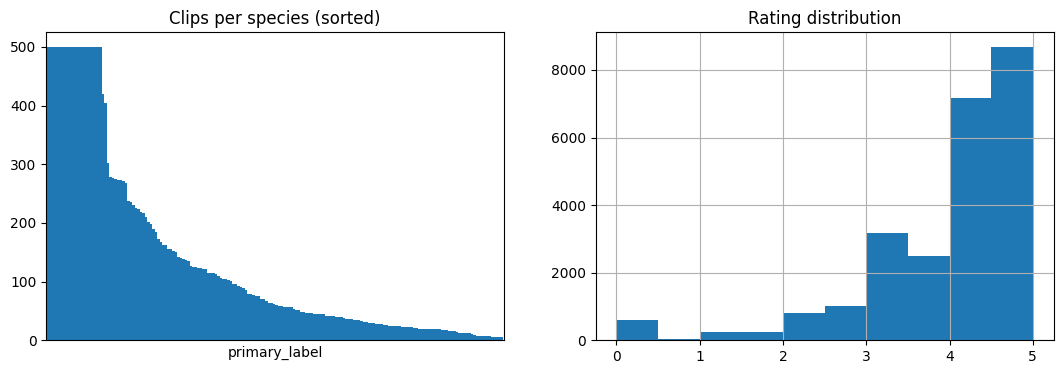

In [10]:
counts = meta.primary_label.value_counts()
print("species:", counts.shape[0])
print(counts.describe())
print("\nRarest 10:\n", counts.tail(10))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind="bar", ax=ax[0], width=1.0); ax[0].set_xticks([])
ax[0].set_title("Clips per species (sorted)")
meta.rating.hist(ax=ax[1], bins=10); ax[1].set_title("Rating distribution")
plt.show()

In [11]:
import ast
sec = meta.secondary_labels.apply(lambda s: len(ast.literal_eval(s)) if isinstance(s, str) else 0)
print("clips with at least one secondary species:", (sec > 0).mean().round(3))
print(sec.value_counts().head())

clips with at least one secondary species: 0.077
secondary_labels
0    22567
1     1415
2      304
3      110
4       40
Name: count, dtype: int64


In [12]:
import soundfile as sf, os
sample = meta.sample(300, random_state=0)
durs, srs = [], set()
for fn in sample.filename:
    info = sf.info(f"{ROOT}/train_audio/{fn}")
    durs.append(info.duration); srs.add(info.samplerate)
print("sample rates:", srs)
print(pd.Series(durs).describe())
print("unlabeled soundscapes:", len(os.listdir(f"{ROOT}/unlabeled_soundscapes")))

sample rates: {32000}
count     300.000000
mean       61.086939
std       268.943849
min         0.966531
25%        11.217508
50%        24.594281
75%        53.056570
max      4486.536000
dtype: float64
unlabeled soundscapes: 8444


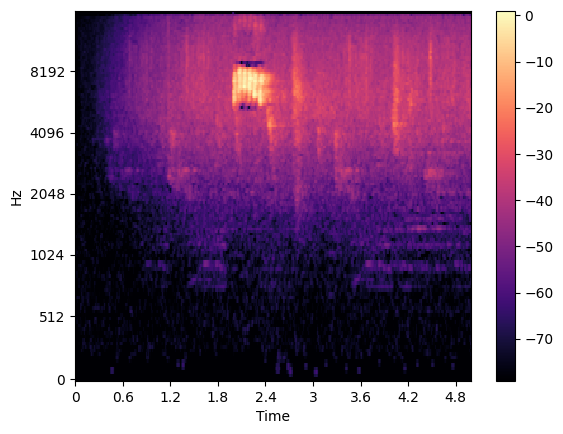

In [13]:
import librosa, librosa.display, IPython.display as ipd
fn = meta.filename.iloc[0]
y, sr = librosa.load(f"{ROOT}/train_audio/{fn}", sr=32000, duration=5)
display(ipd.Audio(y, rate=sr))
S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128))
librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(); plt.show()

In [14]:
!mkdir -p /content/drive/MyDrive/birdclef_project
!cp {ROOT}/train_metadata.csv /content/drive/MyDrive/birdclef_project/

In [15]:
!ls "/content/drive/MyDrive/Colab Notebooks"

'01_eda (1).ipynb'   01_eda.ipynb   Untitled0.ipynb
